# DAZONE 2026 — INT_RF + UPLIFT_RF_CIT + CAFE Feature Engineering

Notebook này là bản tích hợp **chỉ một paper**:

**CAFE — Causally-Guided Automated Feature Engineering with Multi-Agent Reinforcement Learning**

Mục tiêu tích hợp:
- Giữ lại pipeline train hiện tại: **INT_RF** và **UPLIFT_RF_CIT**.
- Thêm nhánh **CAFE feature engineering** để tạo feature mới theo hướng causal-guided.
- Chọn model cuối cùng bằng **Qini Coefficient = qini_cash + qini_card**.

Các điểm tích hợp từ CAFE:
- **Phase I — Causal inductive prior**: chia feature thành nhóm `direct`, `indirect`, `other` theo tín hiệu uplift/Qini, MI và correlation với target.
- **Phase II — Multi-agent-inspired feature generation**: mô phỏng 3 quyết định của CAFE gồm chọn nhóm feature, chọn operator, chọn nhóm feature thứ hai.
- **Reward shaping theo Qini**: feature mới được chọn theo reward ưu tiên Qini trên train fold, causal alignment, diversity và complexity penalty.
- **Không leakage**: CAFE được fit riêng trong từng train fold, rồi mới transform validation/test fold.

Cách chạy feature dropping:
- `COL_IDX = None`: baseline, không drop feature nào.
- `COL_IDX = 0`: drop 1 feature theo ID trong `FEATURE_DROP_PRIORITY_LIST`.
- `COL_IDX = [2, 3, 4, 5]`: drop nhiều feature.
- `COL_IDX = "2:6"`: drop feature ID từ 2 đến 5.

**Bản fix causalml**

- Đã đổi `RUN_INSTALL_CAUSALML = True` để notebook tự cài `causalml` nếu môi trường chưa có.
- Đã thêm hàm `ensure_causalml_ready()` để kiểm tra import thật của `UpliftRandomForestClassifier`.
- Đã sửa thông báo lỗi để hiện lỗi gốc thay vì chỉ báo `causalml is not installed`.


In [1]:
# ============================================================
# 0. MINIMAL ENVIRONMENT SETUP
# ============================================================
# UPLIFT_RF_CIT cần package causalml.
# Bản fix: tự kiểm tra và tự cài causalml nếu môi trường Kaggle/Colab chưa có.
# Nếu môi trường của bạn không cho phép internet/pip install, hãy add một dataset chứa wheel causalml
# hoặc bật Internet trong Notebook Settings rồi chạy lại cell này.

RUN_INSTALL_CAUSALML = True

import importlib
import importlib.util
import subprocess
import sys


def is_installed(import_name: str) -> bool:
    return importlib.util.find_spec(import_name) is not None


def pip_install(package_name: str):
    print(f"Installing missing package: {package_name}")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", package_name])
    importlib.invalidate_caches()


def ensure_causalml_ready() -> bool:
    """Đảm bảo có thể import UpliftRandomForestClassifier từ causalml."""
    global CAUSALML_SETUP_ERROR
    CAUSALML_SETUP_ERROR = None

    try:
        from causalml.inference.tree import UpliftRandomForestClassifier  # noqa: F401
        print("OK: causalml already installed and importable")
        return True
    except Exception as first_error:
        CAUSALML_SETUP_ERROR = first_error

    if not RUN_INSTALL_CAUSALML:
        print("RUN_INSTALL_CAUSALML=False -> skip install")
        print("causalml import error:", repr(CAUSALML_SETUP_ERROR))
        return False

    try:
        pip_install("causalml")
        from causalml.inference.tree import UpliftRandomForestClassifier  # noqa: F401
        print("OK: causalml installed and importable")
        CAUSALML_SETUP_ERROR = None
        return True
    except Exception as second_error:
        CAUSALML_SETUP_ERROR = second_error
        print("ERROR: causalml vẫn chưa import được sau khi cài:", repr(second_error))
        return False


CAUSALML_READY_FROM_SETUP = ensure_causalml_ready()


Installing missing package: causalml
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 65.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 76.9/76.9 kB 5.3 MB/s eta 0:00:00


Failed to import duecredit due to No module named 'duecredit'


OK: causalml installed and importable


In [2]:
# ============================================================
# 1. IMPORTS + GLOBAL CONFIG
# ============================================================
import gc
import os
import re
import time
import warnings
from pathlib import Path

# Giới hạn thread để ổn định runtime trên Kaggle/CPU.
os.environ.setdefault("OMP_NUM_THREADS", "4")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "4")
os.environ.setdefault("MKL_NUM_THREADS", "4")
os.environ.setdefault("NUMEXPR_NUM_THREADS", "4")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.model_selection import StratifiedKFold

try:
    from IPython.display import display
except Exception:
    display = print

warnings.filterwarnings("ignore")

SEED = 42
N_SPLITS = 5
N_JOBS = 4

# INT_RF hyperparameters giữ theo notebook top10 cũ, vì đây là model đang chạy tốt.
RF_N_ESTIMATORS = 320
RF_MAX_DEPTH = 9
RF_MIN_SAMPLES_LEAF = 80
RF_MAX_FEATURES = "sqrt"

# UPLIFT_RF_CIT hyperparameters giữ gọn, đủ mạnh nhưng không quá nặng.
CAUSALML_RF_N_ESTIMATORS = 80
CAUSALML_RF_MAX_DEPTH = 5
CAUSALML_RF_MIN_SAMPLES_LEAF = 120
CAUSALML_RF_MIN_SAMPLES_TREATMENT = 40
CAUSALML_RF_MAX_FEATURES_CAP = 12
CAUSALML_CRITERION = "CIT"

SELECTED_MODEL_NAMES = ["INT_RF", "UPLIFT_RF_CIT"]

# ============================================================
# CAFE CONFIG — chỉ tích hợp paper CAFE
# ============================================================
# RUN_BASELINE_MODELS=True giúp giữ model gốc để so sánh.
# RUN_CAFE_MODELS=True chạy thêm model có feature CAFE.
# best_model cuối cùng vẫn chọn bằng qini_cash + qini_card.
RUN_BASELINE_MODELS = True
RUN_CAFE_MODELS = True
USE_CAFE_FEATURE_ENGINEERING = True

# Phase I: causal role grouping proxy.
CAFE_DIRECT_TOP_K = 14
CAFE_INDIRECT_TOP_K = 14
CAFE_OTHER_TOP_K = 8
CAFE_MI_SAMPLE_SIZE = 15000

# Phase II: CAFE-style operator library.
CAFE_UNARY_OPS = ["sqrt", "log1p_abs", "square", "tanh", "sigmoid"]
CAFE_BINARY_OPS = ["mul", "diff", "ratio", "sum"]
CAFE_GROUP_PAIR_PLAN = [("direct", "direct"), ("direct", "indirect"), ("direct", "other"), ("indirect", "indirect")]
CAFE_MAX_BINARY_PAIRS_PER_PLAN = 120
CAFE_MAX_NEW_FEATURES = 180
CAFE_INCLUDE_ORIGINAL_FEATURES = True

# Reward shaping: ưu tiên Qini, nhưng vẫn cộng causal prior và trừ complexity.
CAFE_QINI_REWARD_WEIGHT = 1.00
CAFE_CAUSAL_BONUS_WEIGHT = 0.08
CAFE_COMPLEXITY_PENALTY_WEIGHT = 0.015
CAFE_MIN_FEATURE_STD = 1e-7
CAFE_EPS = 1e-6

# Import causalml sau khi cell setup đã cố gắng cài package.
# Không dùng thông báo chung chung "causalml is not installed" nữa; lưu lỗi thật để dễ debug.
try:
    from causalml.inference.tree import UpliftRandomForestClassifier
    HAS_CAUSALML = True
    CAUSALML_IMPORT_ERROR = None
    print("causalml: available")
except Exception as e:
    # Nếu người dùng chạy riêng cell này mà bỏ qua cell setup, thử gọi lại helper setup.
    if "ensure_causalml_ready" in globals():
        try:
            HAS_CAUSALML = bool(ensure_causalml_ready())
            if HAS_CAUSALML:
                from causalml.inference.tree import UpliftRandomForestClassifier
                CAUSALML_IMPORT_ERROR = None
                print("causalml: available after setup retry")
            else:
                CAUSALML_IMPORT_ERROR = globals().get("CAUSALML_SETUP_ERROR", e)
        except Exception as retry_error:
            HAS_CAUSALML = False
            CAUSALML_IMPORT_ERROR = retry_error
    else:
        HAS_CAUSALML = False
        CAUSALML_IMPORT_ERROR = e

    if not HAS_CAUSALML:
        print("causalml unavailable -> UPLIFT_RF_CIT sẽ bị skip nếu không xử lý lỗi này:", repr(CAUSALML_IMPORT_ERROR))


causalml: available


## 2. Load dữ liệu + feature dropping

In [3]:
# ============================================================
# 2. LOAD DATA + FEATURE DROPPING CONFIG
# ============================================================

FEATURE_DROP_PRIORITY_LIST = [
    "cnt_month_over3_credit_card_6m",
    "cnt_connected_tls",
    "cnt_earlyterminted_pos",
    "min_sign_vol",
    "cli_contact_region_population_grp",
    "cnt_inbound_tls_12m",
    "cnt_bank_inst_appl_12m",
    "f_approve_last_process",
    "worst_credit_status",
    "cli_contact_region_level",
    "cli_education",
    "f_ever_default",
    "cli_age",
    "cli_job",
    "cnt_earlyterminated_cash",
    "amt_terminated_loan_12m",
    "cnt_noinsurance_loan_24m",
    "cnt_report_bank_6m",
    "ratio_conn_tls_endmonth_12m",
    "ratio_conn_tls_weekend_12m",
    "cli_marital_status",
    "avg_sign_vol",
    "cnt_terminated_loan_12m",
    "cnt_fail_tls_3m",
    "last_offer_limit",
    "cli_emp_period",
    "cnt_fi_inst_appl_12m",
    "cnt_total_payment",
    "risk_grp",
    "cnt_lender_has2pay_last_24m",
    "cnt_month_status1",
    "last_process_channel",
    "cnt_month_from_last_appl",
    "cnt_report_institution_12m",
]

# Tùy chỉnh feature dropping:
#   None -> baseline, không drop feature nào.
#   int  -> drop 1 feature theo ID. Ví dụ: COL_IDX = 0.
#   list/tuple/set/range -> drop nhiều feature. Ví dụ: COL_IDX = [2, 3, 4, 5].
#   list(range(a, b)) -> drop liên tiếp ID a..b-1. Ví dụ: list(range(2, 6)) = 2,3,4,5.
#   string "a:b" -> drop liên tiếp ID a..b-1. Ví dụ: "2:6" = 2,3,4,5.
#   string/list tên feature -> drop trực tiếp theo tên feature gốc. Ví dụ: ["cli_age", "risk_grp"].
#
# Ví dụ chạy:
#   COL_IDX = None
#   COL_IDX = 0
#   COL_IDX = [2, 3]
#   COL_IDX = list(range(2, 6))
#   COL_IDX = "2:6"
COL_IDX = None
feat_path = "/kaggle/input/datasets/tmtrnhelloworld/feature-eng-data-daz/df_feature.csv"
tgt_path = "/kaggle/input/datasets/tmtrnhelloworld/feature-eng-data-daz/df_target.csv"


TARGET_CASH = "cash_sign_30d"
TARGET_CARD = "card_sign_30d"
TREAT_COL_BINARY = "treatment_cash"
TREAT_COL_RAW = "treatment"
ID_CANDIDATES = ["id", "ID", "row_id", "customer_id", "Customer_ID", "client_id", "cli_id", "app_id", "application_id"]




def normalize_feature_drop_selection(selection):
    """Chuẩn hóa cấu hình drop feature.

    Trả về:
    - drop_ids: list ID trong FEATURE_DROP_PRIORITY_LIST.
    - drop_base_cols: list tên feature gốc cần drop.

    Hỗ trợ:
    - None
    - int
    - list/tuple/set/range chứa int hoặc tên feature
    - string "a:b" để drop ID a..b-1
    - string tên feature gốc
    """
    if selection is None:
        return [], []

    def _expand_one(item):
        if isinstance(item, str):
            s = item.strip()
            if not s:
                return []
            if re.fullmatch(r"\d+", s):
                return [int(s)]
            m = re.fullmatch(r"(\d+)\s*:\s*(\d+)", s)
            if m:
                start, stop = int(m.group(1)), int(m.group(2))
                return list(range(start, stop))
            return [s]
        if isinstance(item, (int, np.integer)):
            return [int(item)]
        if isinstance(item, range):
            return list(item)
        if isinstance(item, slice):
            start = 0 if item.start is None else item.start
            stop = len(FEATURE_DROP_PRIORITY_LIST) if item.stop is None else item.stop
            step = 1 if item.step is None else item.step
            return list(range(start, stop, step))
        raise TypeError(
            "COL_IDX chỉ hỗ trợ None, int, range, slice, str, "
            "hoặc list/tuple/set chứa int/tên feature."
        )

    if isinstance(selection, (list, tuple, set, range, np.ndarray, pd.Series)):
        raw_items = []
        for item in list(selection):
            raw_items.extend(_expand_one(item))
    else:
        raw_items = _expand_one(selection)

    drop_ids = []
    drop_base_cols = []
    seen_cols = set()

    for item in raw_items:
        if isinstance(item, (int, np.integer)):
            idx = int(item)
            if idx < 0 or idx >= len(FEATURE_DROP_PRIORITY_LIST):
                raise IndexError(f"COL_IDX={idx} ngoài range 0..{len(FEATURE_DROP_PRIORITY_LIST)-1}")
            base_col = FEATURE_DROP_PRIORITY_LIST[idx]
            if base_col not in seen_cols:
                drop_ids.append(idx)
                drop_base_cols.append(base_col)
                seen_cols.add(base_col)
        elif isinstance(item, str):
            base_col = item.strip()
            if base_col not in FEATURE_DROP_PRIORITY_LIST:
                print(f"WARNING: '{base_col}' không nằm trong FEATURE_DROP_PRIORITY_LIST, vẫn sẽ thử match trong df_feature.")
                idx = None
            else:
                idx = FEATURE_DROP_PRIORITY_LIST.index(base_col)
            if base_col not in seen_cols:
                drop_ids.append(idx)
                drop_base_cols.append(base_col)
                seen_cols.add(base_col)
        else:
            raise TypeError(f"COL_IDX chứa phần tử không hợp lệ: {item!r}")

    return drop_ids, drop_base_cols


def match_base_feature_columns(columns, base_col):
    """Match cột gốc và các cột one-hot/encoded sinh ra từ feature gốc."""
    if base_col is None:
        return []
    return [c for c in columns if c == base_col or c.startswith(f"{base_col}_")]


def make_id_series(source_df, n_rows=None, id_col=None):
    if n_rows is None:
        n_rows = len(source_df)
    if id_col is not None and id_col in source_df.columns:
        return source_df[id_col].reset_index(drop=True).rename(id_col)
    return pd.Series(np.arange(n_rows), name="row_id")


def encode_treatment_cash(feature_df):
    """Return W: 1 = Cash strategy, 0 = Card strategy."""
    if TREAT_COL_BINARY in feature_df.columns:
        return feature_df[TREAT_COL_BINARY].astype(int).to_numpy(), TREAT_COL_BINARY
    if TREAT_COL_RAW not in feature_df.columns:
        raise ValueError("Thiếu cột treatment_cash hoặc treatment trong df_feature.csv")

    s = feature_df[TREAT_COL_RAW]
    if pd.api.types.is_numeric_dtype(s):
        return s.astype(int).to_numpy(), TREAT_COL_RAW

    st = s.astype(str).str.strip().str.lower()
    mapped = np.where(st.str.contains("cash"), 1, np.where(st.str.contains("card"), 0, np.nan))
    if np.isnan(mapped).any():
        bad = sorted(st[pd.isna(mapped)].unique()[:10])
        raise ValueError(f"Không encode được treatment values: {bad}")
    return mapped.astype(int), TREAT_COL_RAW




feat = pd.read_csv(feat_path)
tgt = pd.read_csv(tgt_path)

W, TREAT_COL = encode_treatment_cash(feat)
Y_cash = tgt[TARGET_CASH].astype(int).to_numpy()
Y_card = tgt[TARGET_CARD].astype(int).to_numpy()

ID_COL = next((col for col in ID_CANDIDATES if col in feat.columns), None)
FEATURE_DROP_IDXS, FEATURE_DROP_BASE_COLS = normalize_feature_drop_selection(COL_IDX)
FEATURE_DROP_BASE_COL = None if len(FEATURE_DROP_BASE_COLS) == 0 else "|".join(FEATURE_DROP_BASE_COLS)
FEATURE_DROP_COL_IDX = None if len(FEATURE_DROP_IDXS) == 0 else "|".join("NA" if i is None else str(i) for i in FEATURE_DROP_IDXS)

drop_cols_in_feat = []
for base_col in FEATURE_DROP_BASE_COLS:
    drop_cols_in_feat.extend(match_base_feature_columns(feat.columns, base_col))
# Deduplicate while preserving order.
drop_cols_in_feat = list(dict.fromkeys(drop_cols_in_feat))

index_like_cols = [c for c in feat.columns if c.lower().startswith("unnamed") or c.lower() == "index"]
exclude_cols = set(drop_cols_in_feat + index_like_cols + [TARGET_CASH, TARGET_CARD, TREAT_COL_BINARY, TREAT_COL_RAW])
if ID_COL is not None:
    exclude_cols.add(ID_COL)

FEAT_COLS = [col for col in feat.columns if col not in exclude_cols]
X_df = feat[FEAT_COLS].copy()
X = X_df.to_numpy(dtype=np.float32)

w_cash = (W == 1).astype(int)
w_card = (W == 0).astype(int)

print("=" * 80)
if not FEATURE_DROP_BASE_COLS:
    print("FEATURE DROPPING: baseline, không drop feature nào")
else:
    print(f"FEATURE DROPPING: COL_IDX={COL_IDX}")
    print(f"Drop IDs      : {FEATURE_DROP_IDXS}")
    print(f"Base features : {FEATURE_DROP_BASE_COLS}")
    print(f"Dropped df_feature columns ({len(drop_cols_in_feat)}): {drop_cols_in_feat}")
print("=" * 80)

print(f"N={len(X):,} | features={X.shape[1]}")
print(f"Treatment Cash: {W.sum():,} ({W.mean():.2%}) | Card: {(1-W).sum():,} ({(1-W).mean():.2%})")
print(f"Cash target rate: {Y_cash.mean():.4%} | Card target rate: {Y_card.mean():.4%}")
print("Feature NaN total:", int(pd.isna(X_df).sum().sum()))


FEATURE DROPPING: baseline, không drop feature nào
N=136,992 | features=62
Treatment Cash: 75,612 (55.19%) | Card: 61,380 (44.81%)
Cash target rate: 5.9186% | Card target rate: 2.7111%
Feature NaN total: 0


In [4]:
# ============================================================
# 3. OPTIONAL TEST FEATURE LOADING
# ============================================================
# Notebook chỉ dùng test file đã clean/one-hot tương thích với df_feature.csv.
# Nếu không có test feature đã clean, phần submission sẽ tự skip.


def find_optional_test_feature():
    names = ["df_feature_test.csv", "test_feature.csv", "X_test.csv", "test.csv"]
    roots = [p for p in [Path("/kaggle/input"), Path("/kaggle/working"), Path.cwd(), Path.cwd() / "data", Path("/mnt/data")]
             if p.exists() and str(p.resolve()) not in ["/", "/mnt"]]
    for root in roots:
        for name in names:
            direct = root / name
            if direct.exists():
                return direct
            try:
                hits = list(root.rglob(name))
                if hits:
                    return sorted(hits, key=lambda p: len(str(p)))[0]
            except Exception:
                pass
    return None


def build_test_matrix(test_feature_path):
    test_feat = pd.read_csv(test_feature_path)
    test_id_col = next((col for col in ID_CANDIDATES if col in test_feat.columns), None)
    test_id = make_id_series(test_feat, id_col=test_id_col)

    # Align đúng FEAT_COLS của train: thiếu cột thì fill 0, thừa cột thì bỏ.
    X_test_df = test_feat.reindex(columns=FEAT_COLS, fill_value=0).copy()
    return test_feat, test_id, X_test_df, X_test_df.to_numpy(dtype=np.float32)


test_path = find_optional_test_feature()
if test_path is None:
    test_feat = None
    test_id = None
    X_test_df = None
    X_test = None
    print("Không tìm thấy test feature đã clean -> skip submission.")
else:
    test_feat, test_id, X_test_df, X_test = build_test_matrix(test_path)
    print("Test feature path:", test_path)
    print(f"X_test shape={X_test.shape}")


Không tìm thấy test feature đã clean -> skip submission.


In [5]:
# ============================================================
# 4. LEAKAGE AUDIT
# ============================================================
FORBIDDEN_FEATURE_COLS = {TARGET_CASH, TARGET_CARD, TREAT_COL_BINARY, TREAT_COL_RAW}
if ID_COL is not None:
    FORBIDDEN_FEATURE_COLS.add(ID_COL)

forbidden_present = sorted([c for c in FEAT_COLS if c in FORBIDDEN_FEATURE_COLS])
assert not forbidden_present, f"DATA LEAKAGE: các cột không được phép đang nằm trong FEAT_COLS: {forbidden_present}"

assert TARGET_CASH not in FEAT_COLS and TARGET_CARD not in FEAT_COLS, "DATA LEAKAGE: target bị đưa vào X"
assert TREAT_COL_BINARY not in FEAT_COLS and TREAT_COL_RAW not in FEAT_COLS, "DATA LEAKAGE: treatment bị đưa vào X"
if ID_COL is not None:
    assert ID_COL not in FEAT_COLS, "DATA LEAKAGE/RISK: ID bị đưa vào X"

feature_drop_audit = pd.DataFrame({
    "base_feature": FEATURE_DROP_PRIORITY_LIST,
    "n_matched_train_cols": [len(match_base_feature_columns(feat.columns, c)) for c in FEATURE_DROP_PRIORITY_LIST],
    "matched_train_cols": [match_base_feature_columns(feat.columns, c) for c in FEATURE_DROP_PRIORITY_LIST],
})

print("Leakage audit: PASSED")
display(feature_drop_audit)


Leakage audit: PASSED


,base_feature,n_matched_train_cols,matched_train_cols
0,cnt_month_over3_credit_card_6m,1,[cnt_month_over3_credit_card_6m]
1,cnt_connected_tls,1,[cnt_connected_tls]
2,cnt_earlyterminted_pos,1,[cnt_earlyterminted_pos]
3,min_sign_vol,1,[min_sign_vol]
4,cli_contact_region_population_grp,3,"[cli_contact_region_population_grp_RURAL, cli_..."
5,cnt_inbound_tls_12m,1,[cnt_inbound_tls_12m]
6,cnt_bank_inst_appl_12m,1,[cnt_bank_inst_appl_12m]
7,f_approve_last_process,1,[f_approve_last_process]
8,worst_credit_status,1,[worst_credit_status]
9,cli_contact_region_level,2,"[cli_contact_region_level_North, cli_contact_r..."


## 3. Qini metric + fold cố định

In [6]:
# ============================================================
# 5. QINI METRIC + FIXED FOLDS
# ============================================================
_trapz = np.trapezoid if hasattr(np, "trapezoid") else np.trapz


def qini_curve(y, w_event, score):
    y = np.asarray(y, dtype=float)
    w_event = np.asarray(w_event, dtype=int)
    score = np.asarray(score, dtype=float)

    order = np.argsort(-score, kind="mergesort")
    y_s = y[order]
    w_s = w_event[order]

    n_t = max(int(w_event.sum()), 1)
    n_c = max(len(w_event) - n_t, 1)
    q = np.cumsum(y_s * w_s) / n_t - np.cumsum(y_s * (1 - w_s)) / n_c
    x = np.arange(1, len(y) + 1) / len(y)
    return np.r_[0.0, x], np.r_[0.0, q]


def oracle_score(y, w_event):
    y = np.asarray(y, dtype=int)
    w_event = np.asarray(w_event, dtype=int)
    return w_event * y - (1 - w_event) * y


def qini_metrics(y, w_event, score):
    x, q = qini_curve(y, w_event, score)
    auc_model = float(_trapz(q, x))
    ate = float(q[-1])
    auc_random = ate * 0.5
    _, q_perfect = qini_curve(y, w_event, oracle_score(y, w_event))
    auc_perfect = float(_trapz(q_perfect, x))

    qini_diff = auc_model - auc_random
    denom = auc_perfect - auc_random
    qini_norm = qini_diff / denom if abs(denom) > 1e-12 else np.nan
    qini_ratio = auc_model / auc_random if abs(auc_random) > 1e-12 else np.nan
    return {
        "ate": ate,
        "auc_model": auc_model,
        "auc_random": auc_random,
        "auc_perfect": auc_perfect,
        "qini_diff": qini_diff,
        "qini_norm": qini_norm,
        "qini_ratio": qini_ratio,
    }


def make_fold_id(w_event, y):
    key = (np.asarray(w_event, dtype=int) * 2 + np.asarray(y, dtype=int)).astype(int)
    skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
    fold_id = np.zeros(len(y), dtype=int)
    dummy_x = np.zeros(len(y))
    for fold, (_, va) in enumerate(skf.split(dummy_x, key), 1):
        fold_id[va] = fold
    return fold_id


fold_ids = {
    "cash": make_fold_id(w_cash, Y_cash),
    "card": make_fold_id(w_card, Y_card),
}

print("Fold distribution cash target:", pd.Series(fold_ids["cash"]).value_counts().sort_index().to_dict())
print("Fold distribution card target:", pd.Series(fold_ids["card"]).value_counts().sort_index().to_dict())


Fold distribution cash target: {1: 27399, 2: 27399, 3: 27398, 4: 27398, 5: 27398}
Fold distribution card target: {1: 27399, 2: 27399, 3: 27398, 4: 27398, 5: 27398}


## 4. CAFE — Causally-Guided Automated Feature Engineering

Phần này tích hợp ý tưởng của paper **CAFE** vào pipeline hiện tại theo hướng thực dụng cho DAZONE:

- Dùng causal prior mềm thay vì ràng buộc cứng.
- Chia feature thành nhóm `direct`, `indirect`, `other`.
- Tạo feature mới bằng operator unary/binary.
- Chọn feature mới theo reward có thành phần chính là **Qini trên train fold**.
- Fit CAFE riêng trong từng fold để tránh leakage.

In [7]:
# ============================================================
# 6. CAFE — CAUSALLY-GUIDED AUTOMATED FEATURE ENGINEERING
# ============================================================
# Đây là bản practical adaptation của CAFE cho DAZONE.
# Không dùng DQN đầy đủ để tránh runtime quá nặng trên Kaggle.
# Vẫn giữ đúng tinh thần paper:
#   Phase I : causal role grouping -> direct / indirect / other
#   Phase II: group agent + operator agent + secondary group agent
#   Reward : Qini reward + causal alignment + complexity penalty

CAFE_FEATURE_ROWS = []
CAFE_GROUP_ROWS = []


def _cafe_as_float32(X_input):
    if isinstance(X_input, pd.DataFrame):
        arr = X_input.to_numpy(dtype=np.float32)
    else:
        arr = np.asarray(X_input, dtype=np.float32)
    arr = np.nan_to_num(arr, nan=0.0, posinf=1e6, neginf=-1e6)
    return arr.astype(np.float32, copy=False)


def _cafe_scale01(v):
    v = np.asarray(v, dtype=float)
    v = np.nan_to_num(v, nan=0.0, posinf=0.0, neginf=0.0)
    lo, hi = np.nanmin(v), np.nanmax(v)
    if not np.isfinite(lo) or not np.isfinite(hi) or abs(hi - lo) < 1e-12:
        return np.zeros_like(v, dtype=float)
    return (v - lo) / (hi - lo)


def _cafe_abs_corr_vec(Xn, z):
    Xn = _cafe_as_float32(Xn)
    z = np.asarray(z, dtype=np.float32)
    z = np.nan_to_num(z, nan=0.0, posinf=0.0, neginf=0.0)
    zc = z - z.mean()
    Xc = Xn - Xn.mean(axis=0, keepdims=True)
    denom = np.sqrt((Xc * Xc).sum(axis=0) * float((zc * zc).sum())) + 1e-12
    corr = (Xc.T @ zc) / denom
    return np.abs(np.nan_to_num(corr, nan=0.0, posinf=0.0, neginf=0.0))


def _cafe_best_qini_orientation(y, w_event, score):
    score = np.asarray(score, dtype=float)
    if np.nanstd(score) < CAFE_MIN_FEATURE_STD:
        return 0.0, 1.0

    q_pos = qini_metrics(y, w_event, score)["qini_norm"]
    q_neg = qini_metrics(y, w_event, -score)["qini_norm"]

    q_pos = -1e9 if not np.isfinite(q_pos) else float(q_pos)
    q_neg = -1e9 if not np.isfinite(q_neg) else float(q_neg)

    if q_neg > q_pos:
        return q_neg, -1.0
    return q_pos, 1.0


def _cafe_safe_name(text):
    text = str(text)
    text = re.sub(r"[^A-Za-z0-9_]+", "_", text)
    text = re.sub(r"_+", "_", text).strip("_")
    return text[:120] or "feature"


class CAFEFeatureEngineer:
    """CAFE practical adaptation for fold-safe uplift feature engineering."""

    def __init__(
        self,
        max_new_features=CAFE_MAX_NEW_FEATURES,
        direct_top_k=CAFE_DIRECT_TOP_K,
        indirect_top_k=CAFE_INDIRECT_TOP_K,
        other_top_k=CAFE_OTHER_TOP_K,
        random_state=SEED,
    ):
        self.max_new_features = int(max_new_features)
        self.direct_top_k = int(direct_top_k)
        self.indirect_top_k = int(indirect_top_k)
        self.other_top_k = int(other_top_k)
        self.random_state = int(random_state)
        self.feature_names_ = None
        self.groups_ = {}
        self.base_scores_ = None
        self.selected_recipes_ = []
        self.selected_feature_names_ = []
        self.target_name_ = None
        self.fold_ = None

    def _make_pseudo_uplift_target(self, y, w_event):
        y = np.asarray(y, dtype=np.float32)
        w_event = np.asarray(w_event, dtype=np.float32)
        e = float(np.clip(w_event.mean(), 0.02, 0.98))
        pseudo = y * (w_event / e - (1.0 - w_event) / (1.0 - e))
        return np.nan_to_num(pseudo, nan=0.0, posinf=0.0, neginf=0.0)

    def _estimate_mi(self, Xn, y):
        n = len(Xn)
        if n == 0:
            return np.zeros(Xn.shape[1], dtype=float)
        if n > CAFE_MI_SAMPLE_SIZE:
            rng = np.random.default_rng(self.random_state)
            idx = rng.choice(n, size=CAFE_MI_SAMPLE_SIZE, replace=False)
            X_mi, y_mi = Xn[idx], np.asarray(y)[idx]
        else:
            X_mi, y_mi = Xn, np.asarray(y)
        try:
            mi = mutual_info_classif(X_mi, y_mi, discrete_features=False, random_state=self.random_state)
            return np.nan_to_num(mi, nan=0.0, posinf=0.0, neginf=0.0)
        except Exception:
            return np.zeros(Xn.shape[1], dtype=float)

    def _build_causal_groups(self, Xn, y, w_event):
        n_features = Xn.shape[1]
        pseudo = self._make_pseudo_uplift_target(y, w_event)

        corr_uplift = _cafe_abs_corr_vec(Xn, pseudo)
        corr_y = _cafe_abs_corr_vec(Xn, y)
        mi = self._estimate_mi(Xn, y)

        # Direct feature score: feature nào tự nó ranking uplift tốt hơn thì ưu tiên cao.
        qini_uni = np.zeros(n_features, dtype=float)
        qini_sign = np.ones(n_features, dtype=float)
        for j in range(n_features):
            qini_uni[j], qini_sign[j] = _cafe_best_qini_orientation(y, w_event, Xn[:, j])

        base_score = (
            0.45 * _cafe_scale01(qini_uni)
            + 0.25 * _cafe_scale01(corr_uplift)
            + 0.20 * _cafe_scale01(mi)
            + 0.10 * _cafe_scale01(corr_y)
        )
        self.base_scores_ = base_score

        order = np.argsort(-base_score, kind="mergesort")
        direct = list(order[: min(self.direct_top_k, n_features)])

        remaining = [j for j in range(n_features) if j not in set(direct)]
        if direct and remaining:
            direct_mat = Xn[:, direct]
            rem_mat = Xn[:, remaining]
            # Correlation proxy để tìm feature indirect/mediated quanh nhóm direct.
            rem_center = rem_mat - rem_mat.mean(axis=0, keepdims=True)
            dir_center = direct_mat - direct_mat.mean(axis=0, keepdims=True)
            denom = np.sqrt((rem_center * rem_center).sum(axis=0)[:, None] * (dir_center * dir_center).sum(axis=0)[None, :]) + 1e-12
            corr_mat = np.abs((rem_center.T @ dir_center) / denom)
            max_corr_to_direct = np.nan_to_num(corr_mat, nan=0.0, posinf=0.0, neginf=0.0).max(axis=1)
            indirect_score = 0.65 * _cafe_scale01(max_corr_to_direct) + 0.35 * _cafe_scale01(base_score[remaining])
            indirect_order = np.argsort(-indirect_score, kind="mergesort")
            indirect = [remaining[i] for i in indirect_order[: min(self.indirect_top_k, len(remaining))]]
        else:
            indirect = []

        used = set(direct + indirect)
        other_candidates = [j for j in order if j not in used]
        other = list(other_candidates[: min(self.other_top_k, len(other_candidates))])

        self.groups_ = {"direct": direct, "indirect": indirect, "other": other}
        return self.groups_

    def _apply_unary(self, Xn, op, i):
        x = Xn[:, i].astype(np.float32)
        if op == "sqrt":
            z = np.sqrt(np.abs(x))
        elif op == "log1p_abs":
            z = np.log1p(np.abs(x))
        elif op == "square":
            z = x * x
        elif op == "tanh":
            z = np.tanh(x)
        elif op == "sigmoid":
            z = 1.0 / (1.0 + np.exp(-np.clip(x, -30, 30)))
        else:
            raise ValueError(op)
        return np.nan_to_num(z, nan=0.0, posinf=1e6, neginf=-1e6).astype(np.float32)

    def _apply_binary(self, Xn, op, i, j):
        a = Xn[:, i].astype(np.float32)
        b = Xn[:, j].astype(np.float32)
        if op == "mul":
            z = a * b
        elif op == "diff":
            z = a - b
        elif op == "ratio":
            z = a / (np.abs(b) + CAFE_EPS)
        elif op == "sum":
            z = a + b
        else:
            raise ValueError(op)
        z = np.clip(z, -1e6, 1e6)
        return np.nan_to_num(z, nan=0.0, posinf=1e6, neginf=-1e6).astype(np.float32)

    def _recipe_to_name(self, recipe):
        if recipe["arity"] == 1:
            return f"cafe_{self.target_name_}_{recipe['group1']}_{recipe['op']}__{_cafe_safe_name(self.feature_names_[recipe['i']])}"
        return (
            f"cafe_{self.target_name_}_{recipe['group1']}_x_{recipe['group2']}_{recipe['op']}__"
            f"{_cafe_safe_name(self.feature_names_[recipe['i']])}__{_cafe_safe_name(self.feature_names_[recipe['j']])}"
        )

    def _causal_prior(self, group1, group2=None):
        weights = {"direct": 1.00, "indirect": 0.60, "other": 0.20}
        if group2 is None:
            return weights.get(group1, 0.0)
        return 0.5 * weights.get(group1, 0.0) + 0.5 * weights.get(group2, 0.0)

    def _evaluate_candidate(self, values, y, w_event, group1, group2=None, complexity=1):
        qini_score, sign = _cafe_best_qini_orientation(y, w_event, values)
        causal_bonus = self._causal_prior(group1, group2)
        reward = (
            CAFE_QINI_REWARD_WEIGHT * qini_score
            + CAFE_CAUSAL_BONUS_WEIGHT * causal_bonus
            - CAFE_COMPLEXITY_PENALTY_WEIGHT * complexity
        )
        return float(reward), float(qini_score), float(sign), float(causal_bonus)

    def fit(self, X_train, y, w_event, feature_names=None, target_name="target", fold=None):
        Xn = _cafe_as_float32(X_train)
        y = np.asarray(y, dtype=int)
        w_event = np.asarray(w_event, dtype=int)

        self.target_name_ = str(target_name)
        self.fold_ = fold
        self.feature_names_ = list(feature_names) if feature_names is not None else [f"f{i}" for i in range(Xn.shape[1])]

        groups = self._build_causal_groups(Xn, y, w_event)
        candidates = []

        # Agent 1 chọn group; Agent operator chọn unary op.
        for group_name in ["direct", "indirect", "other"]:
            for i in groups.get(group_name, []):
                for op in CAFE_UNARY_OPS:
                    values = self._apply_unary(Xn, op, i)
                    reward, qini_score, sign, causal_bonus = self._evaluate_candidate(values, y, w_event, group_name, None, complexity=1)
                    recipe = {"arity": 1, "op": op, "i": int(i), "group1": group_name, "sign": sign}
                    candidates.append((reward, qini_score, causal_bonus, recipe))

        # Agent 1 chọn group chính; Operator chọn binary op; Agent 2 chọn group phụ.
        for group1, group2 in CAFE_GROUP_PAIR_PLAN:
            idx1 = groups.get(group1, [])
            idx2 = groups.get(group2, [])
            if not idx1 or not idx2:
                continue
            pair_count = 0
            for i in idx1:
                for j in idx2:
                    if i == j:
                        continue
                    if group1 == group2 and j <= i:
                        continue
                    for op in CAFE_BINARY_OPS:
                        values = self._apply_binary(Xn, op, i, j)
                        reward, qini_score, sign, causal_bonus = self._evaluate_candidate(values, y, w_event, group1, group2, complexity=2)
                        recipe = {"arity": 2, "op": op, "i": int(i), "j": int(j), "group1": group1, "group2": group2, "sign": sign}
                        candidates.append((reward, qini_score, causal_bonus, recipe))
                    pair_count += 1
                    if pair_count >= CAFE_MAX_BINARY_PAIRS_PER_PLAN:
                        break
                if pair_count >= CAFE_MAX_BINARY_PAIRS_PER_PLAN:
                    break

        candidates = sorted(candidates, key=lambda x: x[0], reverse=True)

        # Greedy diversity: tránh lấy quá nhiều feature trùng cùng một base feature/operator.
        selected = []
        seen_keys = set()
        for reward, qini_score, causal_bonus, recipe in candidates:
            if recipe["arity"] == 1:
                key = (recipe["arity"], recipe["op"], recipe["i"])
            else:
                key = (recipe["arity"], recipe["op"], min(recipe["i"], recipe["j"]), max(recipe["i"], recipe["j"]))
            if key in seen_keys:
                continue
            selected.append((reward, qini_score, causal_bonus, recipe))
            seen_keys.add(key)
            if len(selected) >= self.max_new_features:
                break

        self.selected_recipes_ = [x[3] for x in selected]
        self.selected_feature_names_ = [self._recipe_to_name(recipe) for recipe in self.selected_recipes_]

        CAFE_GROUP_ROWS.append({
            "target": self.target_name_,
            "fold": self.fold_,
            "n_direct": len(groups.get("direct", [])),
            "n_indirect": len(groups.get("indirect", [])),
            "n_other": len(groups.get("other", [])),
            "direct_features": "|".join(self.feature_names_[i] for i in groups.get("direct", [])),
            "indirect_features": "|".join(self.feature_names_[i] for i in groups.get("indirect", [])),
            "other_features": "|".join(self.feature_names_[i] for i in groups.get("other", [])),
            "n_selected_cafe_features": len(self.selected_recipes_),
        })

        for rank, (reward, qini_score, causal_bonus, recipe) in enumerate(selected, 1):
            CAFE_FEATURE_ROWS.append({
                "target": self.target_name_,
                "fold": self.fold_,
                "rank": rank,
                "feature_name": self._recipe_to_name(recipe),
                "reward": reward,
                "qini_train_single_feature": qini_score,
                "causal_bonus": causal_bonus,
                "arity": recipe["arity"],
                "operator": recipe["op"],
                "group1": recipe["group1"],
                "group2": recipe.get("group2", ""),
                "base_feature_1": self.feature_names_[recipe["i"]],
                "base_feature_2": "" if recipe["arity"] == 1 else self.feature_names_[recipe["j"]],
                "sign": recipe["sign"],
            })

        print(
            f"  [CAFE] target={self.target_name_} fold={self.fold_} | "
            f"groups direct/indirect/other={len(groups.get('direct', []))}/"
            f"{len(groups.get('indirect', []))}/{len(groups.get('other', []))} | "
            f"selected={len(self.selected_recipes_)}"
        )
        return self

    def _apply_recipe(self, Xn, recipe):
        if recipe["arity"] == 1:
            z = self._apply_unary(Xn, recipe["op"], recipe["i"])
        else:
            z = self._apply_binary(Xn, recipe["op"], recipe["i"], recipe["j"])
        return (recipe["sign"] * z).astype(np.float32)

    def transform(self, X_input):
        Xn = _cafe_as_float32(X_input)
        if not self.selected_recipes_:
            return Xn.copy()

        new_cols = [self._apply_recipe(Xn, recipe) for recipe in self.selected_recipes_]
        X_new = np.column_stack(new_cols).astype(np.float32)
        X_new = np.nan_to_num(X_new, nan=0.0, posinf=1e6, neginf=-1e6)

        if CAFE_INCLUDE_ORIGINAL_FEATURES:
            return np.c_[Xn, X_new].astype(np.float32)
        return X_new.astype(np.float32)

    def get_feature_names_out(self):
        if CAFE_INCLUDE_ORIGINAL_FEATURES:
            return list(self.feature_names_) + list(self.selected_feature_names_)
        return list(self.selected_feature_names_)

## 5. Model helpers: INT_RF + UPLIFT_RF_CIT

In [8]:
# ============================================================
# 6. MODEL HELPERS
# ============================================================
class ConstantClassifier:
    def __init__(self, value):
        self.value = float(value)
        self.classes_ = np.array([0, 1])

    def fit(self, X, y, sample_weight=None):
        return self

    def predict_proba(self, X):
        p = np.full(len(X), self.value, dtype=float)
        p = np.clip(p, 0.0, 1.0)
        return np.c_[1 - p, p]


def make_rf_classifier(seed=SEED):
    return RandomForestClassifier(
        n_estimators=RF_N_ESTIMATORS,
        max_depth=RF_MAX_DEPTH,
        min_samples_leaf=RF_MIN_SAMPLES_LEAF,
        max_features=RF_MAX_FEATURES,
        class_weight="balanced_subsample",
        n_jobs=N_JOBS,
        random_state=seed,
    )


def class_weights(y, pos_weight=None):
    y = np.asarray(y, dtype=int)
    if pos_weight is None:
        pos = max(int(y.sum()), 1)
        neg = max(len(y) - pos, 1)
        pos_weight = neg / pos
    return np.where(y == 1, pos_weight, 1.0).astype(np.float32)


def fit_classifier(X_train, y_train, sample_weight=None, seed=SEED):
    y_train = np.asarray(y_train, dtype=int)
    if len(y_train) == 0 or len(np.unique(y_train)) < 2:
        return ConstantClassifier(float(y_train.mean()) if len(y_train) else 0.0)

    model = make_rf_classifier(seed=seed)
    if sample_weight is None:
        model.fit(X_train, y_train)
    else:
        model.fit(X_train, y_train, sample_weight=np.asarray(sample_weight, dtype=np.float32))
    return model


def predict_classifier(model, X_pred):
    proba = np.asarray(model.predict_proba(X_pred))
    if proba.ndim == 1:
        return np.clip(proba.astype(float), 0.0, 1.0)
    if proba.shape[1] == 1:
        classes = getattr(model, "classes_", np.array([1]))
        return np.full(len(X_pred), float(classes[0] == 1))
    classes = list(getattr(model, "classes_", [0, 1]))
    idx = classes.index(1) if 1 in classes else -1
    return proba[:, idx].astype(float)


def fold_iter(target_name):
    fid = fold_ids[target_name]
    for fold in range(1, N_SPLITS + 1):
        va = np.where(fid == fold)[0]
        tr = np.where(fid != fold)[0]
        yield fold, tr, va


def get_target_arrays(target_name):
    if target_name == "cash":
        # Event treatment = Cash, control = Card.
        return Y_cash, w_cash, "CASH"
    if target_name == "card":
        # Event treatment = Card, control = Cash.
        return Y_card, w_card, "CARD"
    raise ValueError(target_name)


def print_fold_metric(fold, target_name, y, w_event, va, pred):
    met = qini_metrics(y[va], w_event[va], pred)
    print(f"  fold {fold}: Qini_coefficient_{target_name}={met['qini_norm']:+.5f} | Q_ratio={met['qini_ratio']:+.4f}")
    return met


def extract_uplift_prediction(pred_raw):
    """Chuẩn hóa output từ causalml về vector uplift 1D."""
    if isinstance(pred_raw, pd.DataFrame):
        num = pred_raw.select_dtypes(include=[np.number])
        for c in ["uplift", "treatment_effect", "maxTreatmentEffect", "recommended_treatment_effect"]:
            if c in num.columns:
                return num[c].to_numpy(dtype=float)
        return num.iloc[:, -1].to_numpy(dtype=float)

    arr = np.asarray(pred_raw)
    if arr.ndim == 1:
        return arr.astype(float)
    if arr.shape[1] >= 2:
        return (arr[:, 1] - arr[:, 0]).astype(float)
    return arr[:, 0].astype(float)


def build_fold_feature_matrices(target_name, fold, tr, va, X_test_input=None, use_cafe=False):
    """Return fold-specific matrices. CAFE is fit only on train fold to avoid leakage."""
    if not use_cafe:
        return X[tr], X[va], X_test_input, None

    y, w_event, _ = get_target_arrays(target_name)
    cafe = CAFEFeatureEngineer(random_state=SEED + 1000 * fold + (1 if target_name == "cash" else 2))
    cafe.fit(
        X[tr],
        y[tr],
        w_event[tr],
        feature_names=FEAT_COLS,
        target_name=target_name,
        fold=fold,
    )

    X_tr_cafe = cafe.transform(X[tr])
    X_va_cafe = cafe.transform(X[va])
    X_te_cafe = cafe.transform(X_test_input) if X_test_input is not None else None
    return X_tr_cafe, X_va_cafe, X_te_cafe, cafe

In [9]:
# ============================================================
# 7. INT_RF — Interaction S-Learner with Random Forest
# ============================================================
def run_int_rf(target_name, X_test=None, use_cafe=False, model_label="INT_RF"):
    y, w_event, label = get_target_arrays(target_name)
    oof = np.zeros(len(X), dtype=float)
    test_score = np.zeros(len(X_test), dtype=float) if X_test is not None else None

    cafe_tag = " + CAFE" if use_cafe else ""
    print(f"\n[{label}] {model_label}{cafe_tag}")
    for fold, tr, va in fold_iter(target_name):
        Xtr_base, Xva_base, Xte_base, _ = build_fold_feature_matrices(
            target_name=target_name,
            fold=fold,
            tr=tr,
            va=va,
            X_test_input=X_test,
            use_cafe=use_cafe,
        )

        # X_aug = [X, treatment_event_flag, X * treatment_event_flag]
        wt = w_event[tr].astype(np.float32)[:, None]
        Xtr_aug = np.c_[Xtr_base, wt, Xtr_base * wt]

        Xva_event = np.c_[Xva_base, np.ones((len(va), 1), dtype=np.float32), Xva_base]
        Xva_control = np.c_[Xva_base, np.zeros((len(va), 1), dtype=np.float32), np.zeros_like(Xva_base)]

        model = fit_classifier(Xtr_aug, y[tr], sample_weight=class_weights(y[tr]), seed=SEED + fold)
        pred = predict_classifier(model, Xva_event) - predict_classifier(model, Xva_control)
        oof[va] = pred

        if Xte_base is not None:
            Xte_event = np.c_[Xte_base, np.ones((len(Xte_base), 1), dtype=np.float32), Xte_base]
            Xte_control = np.c_[Xte_base, np.zeros((len(Xte_base), 1), dtype=np.float32), np.zeros_like(Xte_base)]
            test_score += (predict_classifier(model, Xte_event) - predict_classifier(model, Xte_control)) / N_SPLITS

        print_fold_metric(fold, target_name, y, w_event, va, pred)
        del model, Xtr_base, Xva_base, Xtr_aug, Xva_event, Xva_control
        gc.collect()

    full_met = qini_metrics(y, w_event, oof)
    print(f"  OOF: Qini_coefficient_{target_name}={full_met['qini_norm']:+.5f} | Q_ratio={full_met['qini_ratio']:+.4f}")
    return oof, test_score

In [10]:
# ============================================================
# 8. UPLIFT_RF_CIT — CausalML Uplift Random Forest criterion=CIT
# ============================================================
def make_causalml_rf(seed, n_features=None):
    if n_features is None:
        n_features = X.shape[1]
    base_kwargs = dict(
        n_estimators=CAUSALML_RF_N_ESTIMATORS,
        max_features=min(CAUSALML_RF_MAX_FEATURES_CAP, int(n_features)),
        max_depth=CAUSALML_RF_MAX_DEPTH,
        min_samples_leaf=CAUSALML_RF_MIN_SAMPLES_LEAF,
        min_samples_treatment=CAUSALML_RF_MIN_SAMPLES_TREATMENT,
        evaluationFunction=CAUSALML_CRITERION,
        control_name="control",
    )
    # CausalML version khác nhau có thể khác signature; thử từ đầy đủ đến tối giản.
    for extra_kwargs in [
        {"n_jobs": N_JOBS, "random_state": seed},
        {"random_state": seed},
        {"n_jobs": N_JOBS},
        {},
    ]:
        try:
            return UpliftRandomForestClassifier(**base_kwargs, **extra_kwargs)
        except TypeError:
            continue
    return UpliftRandomForestClassifier(**base_kwargs)


def run_uplift_rf_cit(target_name, X_test=None, use_cafe=False, model_label="UPLIFT_RF_CIT"):
    if not HAS_CAUSALML:
        raise ImportError(
            "causalml chưa import được. Hãy chạy lại cell 0 để auto-install causalml "
            f"hoặc kiểm tra lỗi gốc: {repr(globals().get('CAUSALML_IMPORT_ERROR', None))}"
        )

    y, w_event, label = get_target_arrays(target_name)
    treatment_labels = np.where(w_event == 1, "treatment", "control")
    oof = np.zeros(len(X), dtype=float)
    test_score = np.zeros(len(X_test), dtype=float) if X_test is not None else None

    cafe_tag = " + CAFE" if use_cafe else ""
    print(f"\n[{label}] {model_label}{cafe_tag}")
    for fold, tr, va in fold_iter(target_name):
        Xtr_base, Xva_base, Xte_base, _ = build_fold_feature_matrices(
            target_name=target_name,
            fold=fold,
            tr=tr,
            va=va,
            X_test_input=X_test,
            use_cafe=use_cafe,
        )

        model = make_causalml_rf(seed=SEED + fold, n_features=Xtr_base.shape[1])
        model.fit(Xtr_base, treatment=treatment_labels[tr], y=y[tr])

        pred = extract_uplift_prediction(model.predict(Xva_base))
        oof[va] = pred

        if Xte_base is not None:
            test_score += extract_uplift_prediction(model.predict(Xte_base)) / N_SPLITS

        print_fold_metric(fold, target_name, y, w_event, va, pred)
        del model, Xtr_base, Xva_base
        gc.collect()

    full_met = qini_metrics(y, w_event, oof)
    print(f"  OOF: Qini_coefficient_{target_name}={full_met['qini_norm']:+.5f} | Q_ratio={full_met['qini_ratio']:+.4f}")
    return oof, test_score

## 6. Chạy baseline + CAFE models

In [11]:
# ============================================================
# 9. RUN SELECTED MODELS
# ============================================================
scores_oof = {"cash": {}, "card": {}}
scores_test = {"cash": {}, "card": {}}
run_log = []


def add_pair_result(model_name, cash_tuple, card_tuple, model_type):
    cash_oof, cash_te = cash_tuple
    card_oof, card_te = card_tuple

    scores_oof["cash"][model_name] = cash_oof
    scores_oof["card"][model_name] = card_oof
    if cash_te is not None:
        scores_test["cash"][model_name] = cash_te
    if card_te is not None:
        scores_test["card"][model_name] = card_te

    row = summarize_one_model(model_name)
    print(f"\n>>> Summary after {model_name}: CASH / CARD / TOTAL")
    display(row.round(6))


def summarize_one_model(model_name):
    row = {"model": model_name}
    row["Qini_coefficient_cash"] = qini_metrics(Y_cash, w_cash, scores_oof["cash"][model_name])["qini_norm"]
    row["Qini_coefficient_card"] = qini_metrics(Y_card, w_card, scores_oof["card"][model_name])["qini_norm"]
    row["Qini_coefficient_total"] = row["Qini_coefficient_cash"] + row["Qini_coefficient_card"]
    return pd.DataFrame([row])


start_all = time.time()

# 1) Baseline INT_RF
if RUN_BASELINE_MODELS:
    try:
        t0 = time.time()
        cash_tuple = run_int_rf("cash", X_test=X_test, use_cafe=False, model_label="INT_RF")
        card_tuple = run_int_rf("card", X_test=X_test, use_cafe=False, model_label="INT_RF")
        add_pair_result("INT_RF", cash_tuple, card_tuple, model_type="interaction_rf")
        run_log.append({"model": "INT_RF", "minutes": (time.time() - t0) / 60, "type": "interaction_rf"})
    except Exception as e:
        print("Skip INT_RF due to error:", repr(e))
        run_log.append({"model": "INT_RF", "minutes": np.nan, "type": "interaction_rf", "error": repr(e)})
        gc.collect()

# 2) Baseline UPLIFT_RF_CIT
if RUN_BASELINE_MODELS:
    try:
        if not HAS_CAUSALML:
            raise ImportError(
                "causalml chưa import được. Hãy chạy lại cell 0 để auto-install causalml "
                f"hoặc kiểm tra lỗi gốc: {repr(globals().get('CAUSALML_IMPORT_ERROR', None))}"
            )
        t0 = time.time()
        cash_tuple = run_uplift_rf_cit("cash", X_test=X_test, use_cafe=False, model_label="UPLIFT_RF_CIT")
        card_tuple = run_uplift_rf_cit("card", X_test=X_test, use_cafe=False, model_label="UPLIFT_RF_CIT")
        add_pair_result("UPLIFT_RF_CIT", cash_tuple, card_tuple, model_type="direct_uplift_causalml")
        run_log.append({"model": "UPLIFT_RF_CIT", "minutes": (time.time() - t0) / 60, "type": "direct_uplift_causalml"})
    except Exception as e:
        print("Skip UPLIFT_RF_CIT due to error:", repr(e))
        run_log.append({"model": "UPLIFT_RF_CIT", "minutes": np.nan, "type": "direct_uplift_causalml", "error": repr(e)})
        gc.collect()

# 3) CAFE_INT_RF — tích hợp CAFE trước Interaction S-Learner
if RUN_CAFE_MODELS and USE_CAFE_FEATURE_ENGINEERING:
    try:
        t0 = time.time()
        cash_tuple = run_int_rf("cash", X_test=X_test, use_cafe=True, model_label="CAFE_INT_RF")
        card_tuple = run_int_rf("card", X_test=X_test, use_cafe=True, model_label="CAFE_INT_RF")
        add_pair_result("CAFE_INT_RF", cash_tuple, card_tuple, model_type="cafe_interaction_rf")
        run_log.append({"model": "CAFE_INT_RF", "minutes": (time.time() - t0) / 60, "type": "cafe_interaction_rf"})
    except Exception as e:
        print("Skip CAFE_INT_RF due to error:", repr(e))
        run_log.append({"model": "CAFE_INT_RF", "minutes": np.nan, "type": "cafe_interaction_rf", "error": repr(e)})
        gc.collect()

# 4) CAFE_UPLIFT_RF_CIT — tích hợp CAFE trước Uplift Random Forest
if RUN_CAFE_MODELS and USE_CAFE_FEATURE_ENGINEERING:
    try:
        if not HAS_CAUSALML:
            raise ImportError(
                "causalml chưa import được. Hãy chạy lại cell 0 để auto-install causalml "
                f"hoặc kiểm tra lỗi gốc: {repr(globals().get('CAUSALML_IMPORT_ERROR', None))}"
            )
        t0 = time.time()
        cash_tuple = run_uplift_rf_cit("cash", X_test=X_test, use_cafe=True, model_label="CAFE_UPLIFT_RF_CIT")
        card_tuple = run_uplift_rf_cit("card", X_test=X_test, use_cafe=True, model_label="CAFE_UPLIFT_RF_CIT")
        add_pair_result("CAFE_UPLIFT_RF_CIT", cash_tuple, card_tuple, model_type="cafe_direct_uplift_causalml")
        run_log.append({"model": "CAFE_UPLIFT_RF_CIT", "minutes": (time.time() - t0) / 60, "type": "cafe_direct_uplift_causalml"})
    except Exception as e:
        print("Skip CAFE_UPLIFT_RF_CIT due to error:", repr(e))
        run_log.append({"model": "CAFE_UPLIFT_RF_CIT", "minutes": np.nan, "type": "cafe_direct_uplift_causalml", "error": repr(e)})
        gc.collect()

print(f"\nTotal runtime: {(time.time() - start_all) / 60:.1f} minutes")
print("Finished models:", list(scores_oof["cash"].keys()))


[CASH] INT_RF
  fold 1: Qini_coefficient_cash=+0.06572 | Q_ratio=+2.0016
  fold 2: Qini_coefficient_cash=+0.04247 | Q_ratio=+1.6466
  fold 3: Qini_coefficient_cash=+0.06787 | Q_ratio=+2.0220
  fold 4: Qini_coefficient_cash=+0.04546 | Q_ratio=+1.6846
  fold 5: Qini_coefficient_cash=+0.05132 | Q_ratio=+1.7673
  OOF: Qini_coefficient_cash=+0.05424 | Q_ratio=+1.8193

[CARD] INT_RF
  fold 1: Qini_coefficient_card=+0.04018 | Q_ratio=+1.9088
  fold 2: Qini_coefficient_card=+0.06066 | Q_ratio=+2.3720
  fold 3: Qini_coefficient_card=+0.05499 | Q_ratio=+2.2870
  fold 4: Qini_coefficient_card=+0.03408 | Q_ratio=+1.7713
  fold 5: Qini_coefficient_card=+0.00994 | Q_ratio=+1.2250
  OOF: Qini_coefficient_card=+0.03991 | Q_ratio=+1.9090

>>> Summary after INT_RF: CASH / CARD / TOTAL


,model,Qini_coefficient_cash,Qini_coefficient_card,Qini_coefficient_total
0,INT_RF,0.054236,0.039909,0.094145



[CASH] UPLIFT_RF_CIT
  fold 1: Qini_coefficient_cash=+0.07236 | Q_ratio=+2.1028
  fold 2: Qini_coefficient_cash=+0.04851 | Q_ratio=+1.7384
  fold 3: Qini_coefficient_cash=+0.06561 | Q_ratio=+1.9880
  fold 4: Qini_coefficient_cash=+0.04865 | Q_ratio=+1.7326
  fold 5: Qini_coefficient_cash=+0.05730 | Q_ratio=+1.8567
  OOF: Qini_coefficient_cash=+0.05721 | Q_ratio=+1.8641

[CARD] UPLIFT_RF_CIT
  fold 1: Qini_coefficient_card=+0.06039 | Q_ratio=+2.3657
  fold 2: Qini_coefficient_card=+0.04432 | Q_ratio=+2.0024
  fold 3: Qini_coefficient_card=+0.03016 | Q_ratio=+1.7058
  fold 4: Qini_coefficient_card=+0.03732 | Q_ratio=+1.8447
  fold 5: Qini_coefficient_card=-0.00304 | Q_ratio=+0.9312
  OOF: Qini_coefficient_card=+0.03251 | Q_ratio=+1.7405

>>> Summary after UPLIFT_RF_CIT: CASH / CARD / TOTAL


,model,Qini_coefficient_cash,Qini_coefficient_card,Qini_coefficient_total
0,UPLIFT_RF_CIT,0.057206,0.032514,0.08972



[CASH] CAFE_INT_RF + CAFE
  [CAFE] target=cash fold=1 | groups direct/indirect/other=14/14/8 | selected=180
  fold 1: Qini_coefficient_cash=+0.05852 | Q_ratio=+1.8918
  [CAFE] target=cash fold=2 | groups direct/indirect/other=14/14/8 | selected=180
  fold 2: Qini_coefficient_cash=+0.05884 | Q_ratio=+1.8957
  [CAFE] target=cash fold=3 | groups direct/indirect/other=14/14/8 | selected=180
  fold 3: Qini_coefficient_cash=+0.05769 | Q_ratio=+1.8687
  [CAFE] target=cash fold=4 | groups direct/indirect/other=14/14/8 | selected=180
  fold 4: Qini_coefficient_cash=+0.04630 | Q_ratio=+1.6972
  [CAFE] target=cash fold=5 | groups direct/indirect/other=14/14/8 | selected=180
  fold 5: Qini_coefficient_cash=+0.05945 | Q_ratio=+1.8890
  OOF: Qini_coefficient_cash=+0.05596 | Q_ratio=+1.8453

[CARD] CAFE_INT_RF + CAFE
  [CAFE] target=card fold=1 | groups direct/indirect/other=14/14/8 | selected=180
  fold 1: Qini_coefficient_card=+0.04191 | Q_ratio=+1.9478
  [CAFE] target=card fold=2 | groups direct/

,model,Qini_coefficient_cash,Qini_coefficient_card,Qini_coefficient_total
0,CAFE_INT_RF,0.055961,0.032946,0.088907



[CASH] CAFE_UPLIFT_RF_CIT + CAFE
  [CAFE] target=cash fold=1 | groups direct/indirect/other=14/14/8 | selected=180
  fold 1: Qini_coefficient_cash=+0.07187 | Q_ratio=+2.0954
  [CAFE] target=cash fold=2 | groups direct/indirect/other=14/14/8 | selected=180
  fold 2: Qini_coefficient_cash=+0.04953 | Q_ratio=+1.7539
  [CAFE] target=cash fold=3 | groups direct/indirect/other=14/14/8 | selected=180
  fold 3: Qini_coefficient_cash=+0.05982 | Q_ratio=+1.9007
  [CAFE] target=cash fold=4 | groups direct/indirect/other=14/14/8 | selected=180
  fold 4: Qini_coefficient_cash=+0.05096 | Q_ratio=+1.7674
  [CAFE] target=cash fold=5 | groups direct/indirect/other=14/14/8 | selected=180
  fold 5: Qini_coefficient_cash=+0.06180 | Q_ratio=+1.9240
  OOF: Qini_coefficient_cash=+0.05751 | Q_ratio=+1.8687

[CARD] CAFE_UPLIFT_RF_CIT + CAFE
  [CAFE] target=card fold=1 | groups direct/indirect/other=14/14/8 | selected=180
  fold 1: Qini_coefficient_card=+0.04496 | Q_ratio=+2.0168
  [CAFE] target=card fold=2 | 

,model,Qini_coefficient_cash,Qini_coefficient_card,Qini_coefficient_total
0,CAFE_UPLIFT_RF_CIT,0.057509,0.034297,0.091806



Total runtime: 63.2 minutes
Finished models: ['INT_RF', 'UPLIFT_RF_CIT', 'CAFE_INT_RF', 'CAFE_UPLIFT_RF_CIT']


## 7. Summary + fold mean

In [12]:
# ============================================================
# 10. SUMMARY TABLES
# ============================================================
def summarize_scores_all():
    rows = []
    models = sorted(set(scores_oof["cash"]).intersection(scores_oof["card"]))
    for model_name in models:
        cash_met = qini_metrics(Y_cash, w_cash, scores_oof["cash"][model_name])
        card_met = qini_metrics(Y_card, w_card, scores_oof["card"][model_name])
        rows.append({
            "model": model_name,
            "Qini_coefficient_cash": cash_met["qini_norm"],
            "Qini_coefficient_card": card_met["qini_norm"],
            "Qini_coefficient_total": cash_met["qini_norm"] + card_met["qini_norm"],
        })
    if not rows:
        return pd.DataFrame(columns=["model", "Qini_coefficient_cash", "Qini_coefficient_card", "Qini_coefficient_total"])
    return pd.DataFrame(rows).sort_values("Qini_coefficient_total", ascending=False).reset_index(drop=True)


def make_fold_qini_table():
    rows = []
    models = sorted(set(scores_oof["cash"]).intersection(scores_oof["card"]))
    for model_name in models:
        for fold in range(1, N_SPLITS + 1):
            idx_cash = fold_ids["cash"] == fold
            idx_card = fold_ids["card"] == fold
            cash_qini = qini_metrics(Y_cash[idx_cash], w_cash[idx_cash], scores_oof["cash"][model_name][idx_cash])["qini_norm"]
            card_qini = qini_metrics(Y_card[idx_card], w_card[idx_card], scores_oof["card"][model_name][idx_card])["qini_norm"]
            rows.append({
                "model": model_name,
                "fold": fold,
                "Qini_coefficient_cash": cash_qini,
                "Qini_coefficient_card": card_qini,
                "Qini_coefficient_total": cash_qini + card_qini,
            })
    return pd.DataFrame(rows).sort_values(["model", "fold"]).reset_index(drop=True)


def make_fold_mean_table(fold_qini_df):
    if fold_qini_df.empty:
        return pd.DataFrame()
    return (
        fold_qini_df
        .groupby("model", as_index=False)
        .agg(
            n_folds=("fold", "nunique"),
            Mean_Qini_coefficient_cash=("Qini_coefficient_cash", "mean"),
            Mean_Qini_coefficient_card=("Qini_coefficient_card", "mean"),
            Mean_Qini_coefficient_total=("Qini_coefficient_total", "mean"),
        )
        .sort_values("Mean_Qini_coefficient_total", ascending=False)
        .reset_index(drop=True)
    )


summary = summarize_scores_all()
fold_qini_logs = make_fold_qini_table()
fold_mean_qini_by_model = make_fold_mean_table(fold_qini_logs)

print("Qini coefficient summary — CASH / CARD / TOTAL")
display(summary.round(6))

print("Fold mean Qini by model")
display(fold_mean_qini_by_model.round(6))

if summary.empty:
    best_model = None
    print("Không có model nào chạy thành công.")
else:
    best_model = summary.iloc[0]["model"]
    best_total = summary.iloc[0]["Qini_coefficient_total"]
    print(f"Best model by Qini_total: {best_model} | Qini_total={best_total:+.6f}")


Qini coefficient summary — CASH / CARD / TOTAL


,model,Qini_coefficient_cash,Qini_coefficient_card,Qini_coefficient_total
0,INT_RF,0.054236,0.039909,0.094145
1,CAFE_UPLIFT_RF_CIT,0.057509,0.034297,0.091806
2,UPLIFT_RF_CIT,0.057206,0.032514,0.089720
3,CAFE_INT_RF,0.055961,0.032946,0.088907


Fold mean Qini by model


,model,n_folds,Mean_Qini_coefficient_cash,Mean_Qini_coefficient_card,Mean_Qini_coefficient_total
0,INT_RF,5,0.054569,0.039971,0.094541
1,CAFE_UPLIFT_RF_CIT,5,0.058795,0.035182,0.093977
2,UPLIFT_RF_CIT,5,0.058484,0.033830,0.092314
3,CAFE_INT_RF,5,0.056161,0.032299,0.088460


Best model by Qini_total: INT_RF | Qini_total=+0.094145


## 8. Qini curves

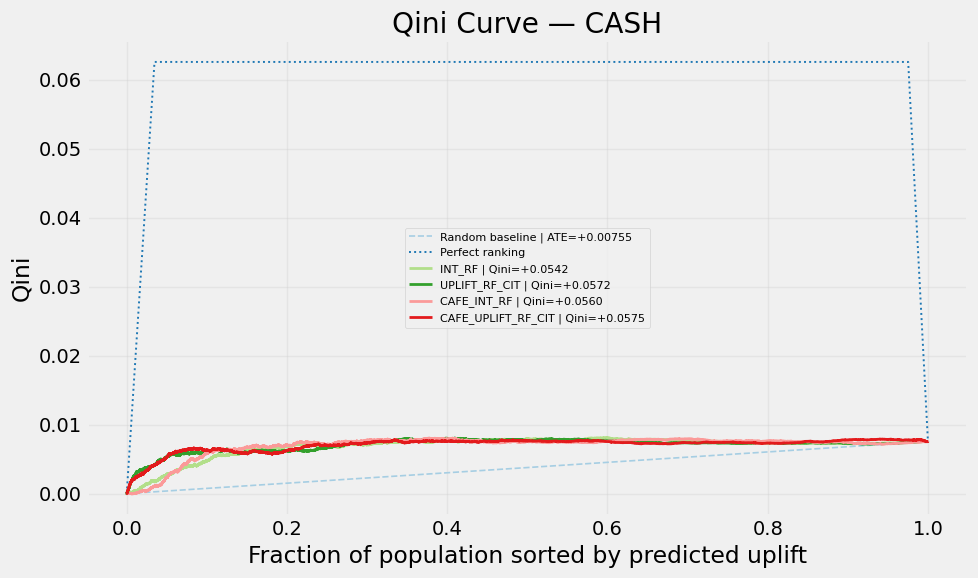

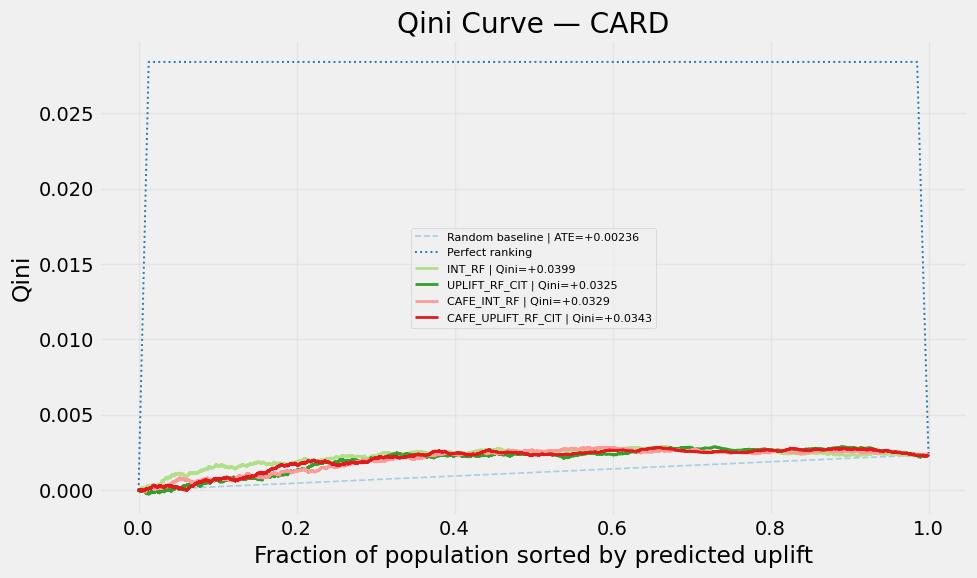

In [13]:
# ============================================================
# 11. QINI CURVES
# ============================================================
def plot_qini_compare(target_name, y, w_event, score_dict):
    if not score_dict:
        print(f"No scores for {target_name}")
        return

    plt.figure(figsize=(10, 6))
    xp, qp = qini_curve(y, w_event, oracle_score(y, w_event))
    ate = qp[-1]
    plt.plot([0, 1], [0, ate], "--", linewidth=1.2, label=f"Random baseline | ATE={ate:+.5f}")
    plt.plot(xp, qp, ":", linewidth=1.4, label="Perfect ranking")

    for model_name, score in score_dict.items():
        x, q = qini_curve(y, w_event, score)
        m = qini_metrics(y, w_event, score)
        plt.plot(x, q, linewidth=2, label=f"{model_name} | Qini={m['qini_norm']:+.4f}")

    plt.title(f"Qini Curve — {target_name.upper()}")
    plt.xlabel("Fraction of population sorted by predicted uplift")
    plt.ylabel("Qini")
    plt.grid(alpha=0.3)
    plt.legend(fontsize=8)
    plt.tight_layout()
    plt.show()


plot_qini_compare("cash", Y_cash, w_cash, scores_oof["cash"])
plot_qini_compare("card", Y_card, w_card, scores_oof["card"])


## 9. Export outputs

In [14]:
# ============================================================
# 12. EXPORT OUTPUTS
# ============================================================
def _safe_run_name(text, max_len=80):
    text = "baseline_all_features" if text is None else str(text)
    text = re.sub(r"[^A-Za-z0-9_.-]+", "_", text)
    return text[:max_len].strip("_") or "run"


BASE_OUTPUT_DIR = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path("outputs")
if not FEATURE_DROP_BASE_COLS:
    RUN_TAG = "baseline_all_features"
else:
    id_part = "ids_" + "-".join("NA" if i is None else str(i) for i in FEATURE_DROP_IDXS)
    name_part = _safe_run_name("__".join(FEATURE_DROP_BASE_COLS), max_len=100)
    RUN_TAG = f"drop_{id_part}_{name_part}"

OUTPUT_DIR = BASE_OUTPUT_DIR / RUN_TAG
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("Output dir:", OUTPUT_DIR)

summary_path = OUTPUT_DIR / "qini_summary.csv"
summary.to_csv(summary_path, index=False)
print("Saved:", summary_path)

fold_path = OUTPUT_DIR / "fold_qini_logs.csv"
fold_qini_logs.to_csv(fold_path, index=False)
print("Saved:", fold_path)

fold_mean_path = OUTPUT_DIR / "fold_mean_qini_by_model.csv"
fold_mean_qini_by_model.to_csv(fold_mean_path, index=False)
print("Saved:", fold_mean_path)

run_log_df = pd.DataFrame(run_log)
run_log_path = OUTPUT_DIR / "run_log.csv"
run_log_df.to_csv(run_log_path, index=False)
print("Saved:", run_log_path)

if CAFE_GROUP_ROWS:
    cafe_groups_df = pd.DataFrame(CAFE_GROUP_ROWS)
    cafe_groups_path = OUTPUT_DIR / "cafe_causal_groups_by_fold.csv"
    cafe_groups_df.to_csv(cafe_groups_path, index=False)
    print("Saved:", cafe_groups_path)

if CAFE_FEATURE_ROWS:
    cafe_features_df = pd.DataFrame(CAFE_FEATURE_ROWS)
    cafe_features_path = OUTPUT_DIR / "cafe_generated_features_by_fold.csv"
    cafe_features_df.to_csv(cafe_features_path, index=False)
    print("Saved:", cafe_features_path)

train_id = make_id_series(feat, id_col=ID_COL)

oof_out = pd.DataFrame()
oof_out[train_id.name] = train_id.values
oof_out["treatment_cash"] = W
oof_out["cash_sign_30d"] = Y_cash
oof_out["card_sign_30d"] = Y_card
oof_out["feature_drop_base_col"] = FEATURE_DROP_BASE_COL
oof_out["feature_drop_col_idx"] = FEATURE_DROP_COL_IDX
oof_out["feature_drop_n_base_cols"] = len(FEATURE_DROP_BASE_COLS)
for name, score in scores_oof["cash"].items():
    oof_out[f"cash_{name}"] = score
for name, score in scores_oof["card"].items():
    oof_out[f"card_{name}"] = score

oof_path = OUTPUT_DIR / "oof_model_scores.csv"
oof_out.to_csv(oof_path, index=False)
print("Saved:", oof_path)

if best_model is not None:
    final_train = pd.DataFrame()
    final_train[train_id.name] = train_id.values
    final_train["feature_drop_base_col"] = FEATURE_DROP_BASE_COL
    final_train["feature_drop_col_idx"] = FEATURE_DROP_COL_IDX
    final_train["feature_drop_n_base_cols"] = len(FEATURE_DROP_BASE_COLS)
    final_train["best_model"] = best_model
    final_train["uplift_cash_score"] = scores_oof["cash"][best_model]
    final_train["uplift_card_score"] = scores_oof["card"][best_model]
    final_train["cash_vs_card_score"] = final_train["uplift_cash_score"] - final_train["uplift_card_score"]
    final_train["recommended_product"] = np.where(final_train["cash_vs_card_score"] >= 0, "Cash", "Card")

    final_train_path = OUTPUT_DIR / "final_scores_train.csv"
    final_train.to_csv(final_train_path, index=False)
    print("Saved:", final_train_path)

    if X_test is not None and best_model in scores_test["cash"] and best_model in scores_test["card"]:
        submission = pd.DataFrame()
        submission[test_id.name] = test_id.values
        submission["best_model"] = best_model
        submission["uplift_cash_score"] = scores_test["cash"][best_model]
        submission["uplift_card_score"] = scores_test["card"][best_model]
        submission["cash_vs_card_score"] = submission["uplift_cash_score"] - submission["uplift_card_score"]
        submission["recommended_product"] = np.where(submission["cash_vs_card_score"] >= 0, "Cash", "Card")

        submission_path = OUTPUT_DIR / "submission.csv"
        submission.to_csv(submission_path, index=False)
        print("Saved:", submission_path)
    else:
        print("Skip submission: không có X_test hoặc best_model không có test score.")
else:
    print("Skip final score export: không có best_model.")

feature_drop_result = {
    "COL_IDX_config": str(COL_IDX),
    "feature_drop_col_idx": FEATURE_DROP_COL_IDX,
    "feature_drop_base_col": FEATURE_DROP_BASE_COL,
    "n_feature_drop_base_cols": len(FEATURE_DROP_BASE_COLS),
    "feature_drop_base_cols": "|".join(FEATURE_DROP_BASE_COLS),
    "n_dropped_train_cols": len(drop_cols_in_feat),
    "dropped_train_cols": "|".join(drop_cols_in_feat),
    "n_features_after_drop": len(FEAT_COLS),
    "use_cafe_feature_engineering": USE_CAFE_FEATURE_ENGINEERING,
    "run_baseline_models": RUN_BASELINE_MODELS,
    "run_cafe_models": RUN_CAFE_MODELS,
    "n_cafe_group_rows": len(CAFE_GROUP_ROWS),
    "n_cafe_feature_rows": len(CAFE_FEATURE_ROWS),
    "best_model": best_model,
}
if best_model is not None:
    best_row = summary.iloc[0].to_dict()
    feature_drop_result.update({
        "best_Qini_coefficient_cash": best_row["Qini_coefficient_cash"],
        "best_Qini_coefficient_card": best_row["Qini_coefficient_card"],
        "best_Qini_coefficient_total": best_row["Qini_coefficient_total"],
    })

feature_drop_result_path = OUTPUT_DIR / "feature_drop_result.csv"
pd.DataFrame([feature_drop_result]).to_csv(feature_drop_result_path, index=False)
print("Saved:", feature_drop_result_path)


Output dir: /kaggle/working/baseline_all_features
Saved: /kaggle/working/baseline_all_features/qini_summary.csv
Saved: /kaggle/working/baseline_all_features/fold_qini_logs.csv
Saved: /kaggle/working/baseline_all_features/fold_mean_qini_by_model.csv
Saved: /kaggle/working/baseline_all_features/run_log.csv
Saved: /kaggle/working/baseline_all_features/cafe_causal_groups_by_fold.csv
Saved: /kaggle/working/baseline_all_features/cafe_generated_features_by_fold.csv
Saved: /kaggle/working/baseline_all_features/oof_model_scores.csv
Saved: /kaggle/working/baseline_all_features/final_scores_train.csv
Skip submission: không có X_test hoặc best_model không có test score.
Saved: /kaggle/working/baseline_all_features/feature_drop_result.csv


## 10. Cách đọc kết quả

Các file quan trọng sau khi chạy:

- `qini_summary.csv`: Qini OOF của tất cả model, gồm baseline và model có CAFE.
- `fold_qini_logs.csv`: Qini từng fold cho từng model.
- `fold_mean_qini_by_model.csv`: Qini trung bình 5 fold.
- `cafe_causal_groups_by_fold.csv`: nhóm feature `direct`, `indirect`, `other` mà CAFE học riêng theo từng target/fold.
- `cafe_generated_features_by_fold.csv`: danh sách feature mới CAFE tạo ra, reward, Qini đơn biến trên train fold, operator và nhóm causal tương ứng.
- `feature_drop_result.csv`: file gọn nhất để so sánh các lần drop feature; đã hỗ trợ drop nhiều feature một lúc qua `COL_IDX = [2, 3, 4, 5]`, `list(range(2, 6))`, hoặc `"2:6"`.
- `final_scores_train.csv`: score uplift Cash/Card và khuyến nghị Cash/Card trên train.
- `submission.csv`: chỉ tạo nếu notebook tìm thấy test feature đã clean/one-hot tương thích với `df_feature.csv`.

Cách hiểu model:
- `INT_RF`, `UPLIFT_RF_CIT`: model gốc.
- `CAFE_INT_RF`, `CAFE_UPLIFT_RF_CIT`: model đã tích hợp **CAFE causal-guided feature engineering** trước khi train.
- `best_model` được chọn theo `Qini_coefficient_total = qini_cash + qini_card`.